# Iowa Housing Prices, Part II: Predictive Modeling

Jose Mariano C. Leechiu

In [ ]:
# Loading the Dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np


df = pd.read_csv("housing.txt")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
# Deal with missing values:
none_cols = ["Alley", "PoolQC", "Fence", "MiscFeature", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

df[none_cols] = df[none_cols].fillna("None")

In [ ]:
# Fill remaining missing values

# 1. Categorical columns
df["MasVnrType"] = df["MasVnrType"].fillna("None")
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

# 2. Numerical columns
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# Check if any missing values remain
print("Remaining missing values:")
print(df.isnull().sum().sum())

Remaining missing values:
0


In [ ]:

# 1. Prepare (X) and (y)
X = df.drop(columns=['Id', 'SalePrice'])
y = df['SalePrice']

# One-hot encode categorical variables
X_encoded = pd.get_dummies(X, drop_first=True)

# 2. Split the data
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# 3. Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train
lasso_model = Lasso(alpha=100.0, max_iter=10000, random_state=42)
lasso_model.fit(X_train_scaled, y_train)

# 5. Evaluate
train_preds = lasso_model.predict(X_train_scaled)
test_preds = lasso_model.predict(X_test_scaled)

print(f"Train R2 Score: {r2_score(y_train, train_preds):.4f}")
print(f"Test R2 Score: {r2_score(y_test, test_preds):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_preds)):.2f}")

Train R2 Score: 0.9346
Test R2 Score: 0.8405
Test RMSE: 34977.87


In [ ]:
from sklearn.linear_model import Ridge

# 1. Train Ridge Regression
ridge_model = Ridge(alpha=100.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)

# 2. Evaluate the model
train_preds_ridge = ridge_model.predict(X_train_scaled)
test_preds_ridge = ridge_model.predict(X_test_scaled)

print(f"Train R2 Score (Ridge): {r2_score(y_train, train_preds_ridge):.4f}")
print(f"Test R2 Score (Ridge): {r2_score(y_test, test_preds_ridge):.4f}")
print(f"Test RMSE (Ridge): {np.sqrt(mean_squared_error(y_test, test_preds_ridge)):.2f}")

Train R2 Score (Ridge): 0.9181
Test R2 Score (Ridge): 0.8616
Test RMSE (Ridge): 32585.50


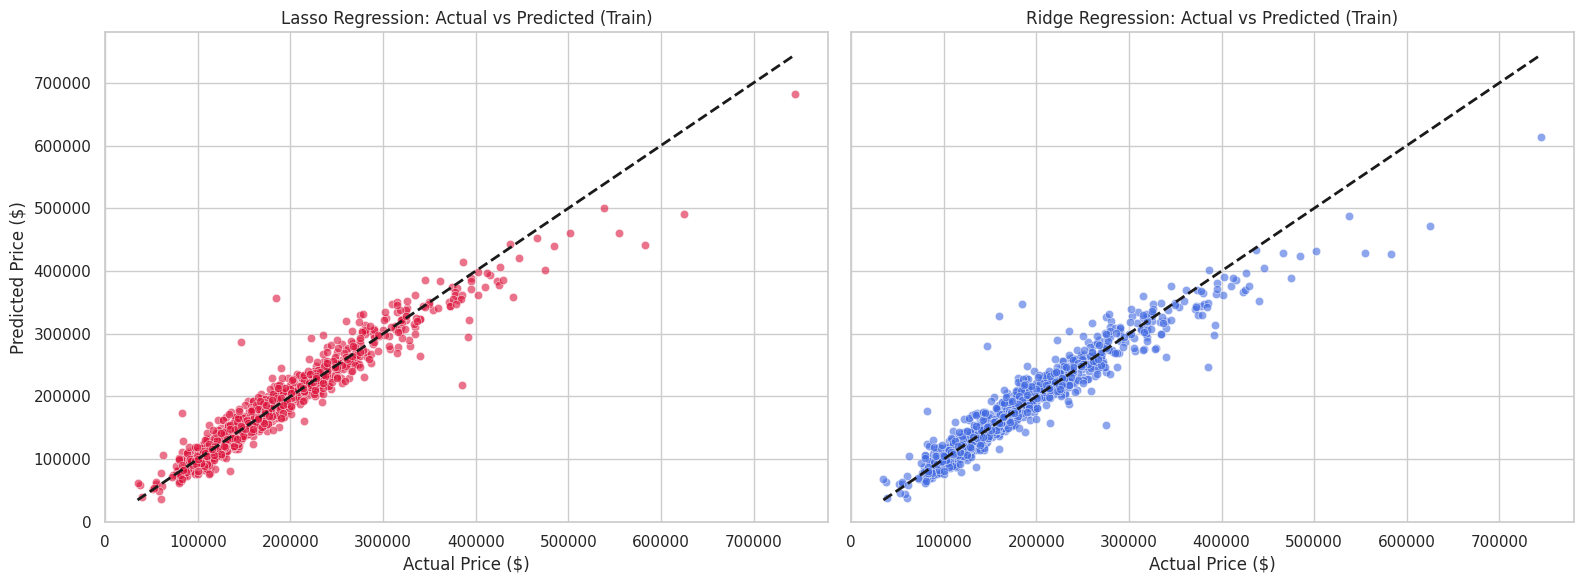

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot 1: Lasso Training
sns.scatterplot(ax=axes[0], x=y_train, y=train_preds, alpha=0.6, color="crimson")
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', lw=2)
axes[0].set_title("Lasso Regression: Actual vs Predicted (Train)")
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")

# Plot 2: Ridge Training
sns.scatterplot(ax=axes[1], x=y_train, y=train_preds_ridge, alpha=0.6, color="royalblue")
axes[1].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', lw=2)
axes[1].set_title("Ridge Regression: Actual vs Predicted (Train)")
axes[1].set_xlabel("Actual Price ($)")

plt.tight_layout()
plt.show()

Train R2 Score (Elastic Net): 0.4512
Test R2 Score (Elastic Net): 0.4253
Test RMSE (Elastic Net): 66393.05
Test MAE (Elastic Net): 43553.05
Number of Non-Zero Coefficients: 255


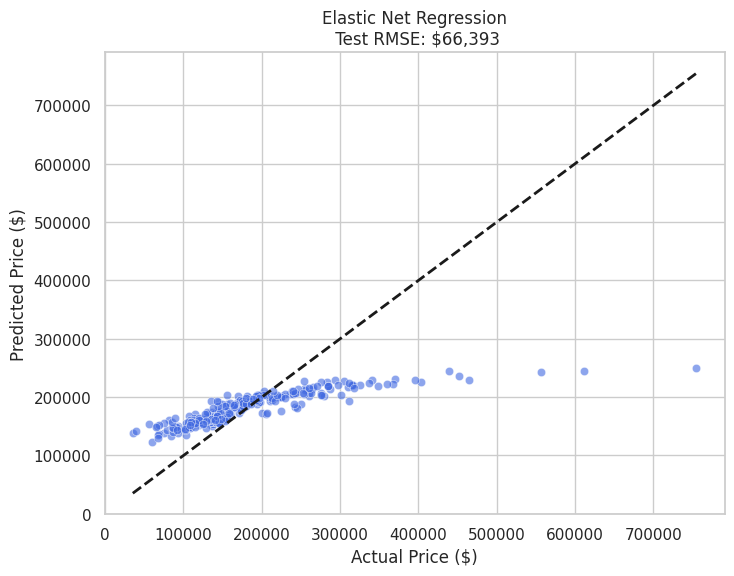

In [ ]:
#Elastic Net
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error

elastic_model = ElasticNet(alpha=50.0, l1_ratio=0.5, max_iter=10000, random_state=42)
elastic_model.fit(X_train_scaled, y_train)

#Predictions
train_preds_elastic = elastic_model.predict(X_train_scaled)
test_preds_elastic = elastic_model.predict(X_test_scaled)

#Evaluation
train_r2_elastic = r2_score(y_train, train_preds_elastic)
test_r2_elastic = r2_score(y_test, test_preds_elastic)
test_rmse_elastic = np.sqrt(mean_squared_error(y_test, test_preds_elastic))
test_mae_elastic = mean_absolute_error(y_test, test_preds_elastic)
n_nonzero_coefs = np.count_nonzero(elastic_model.coef_)

print(f"Train R2 Score (Elastic Net): {train_r2_elastic:.4f}")
print(f"Test R2 Score (Elastic Net): {test_r2_elastic:.4f}")
print(f"Test RMSE (Elastic Net): {test_rmse_elastic:.2f}")
print(f"Test MAE (Elastic Net): {test_mae_elastic:.2f}")
print(f"Number of Non-Zero Coefficients: {n_nonzero_coefs}")

#visualization
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=test_preds_elastic, alpha=0.6, color="royalblue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.title(f"Elastic Net Regression\n Test RMSE: ${test_rmse_elastic:,.0f}")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.show()

Train R² (OLS): 0.9401
Test R² (OLS): 0.0991
Test RMSE (OLS): $83,125.52


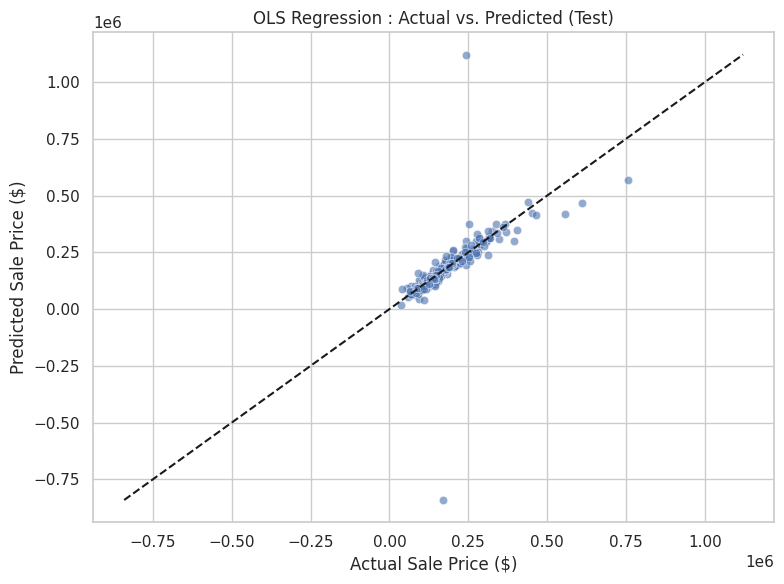

In [ ]:
# OLS

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# fit OLS using the existing training data
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

# make predictions
train_preds_ols = ols_model.predict(X_train_scaled)
test_preds_ols = ols_model.predict(X_test_scaled)

# show results
print(f"Train R² (OLS): {r2_score(y_train, train_preds_ols):.4f}")
print(f"Test R² (OLS): {r2_score(y_test, test_preds_ols):.4f}")
print(f"Test RMSE (OLS): "
      f"${np.sqrt(mean_squared_error(y_test, test_preds_ols)):,.2f}")

# plot actual vs. predicted prices for the test set
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=test_preds_ols, alpha=0.6)

# perfect predictions on dashed line
limits = [
    min(y_test.min(), test_preds_ols.min()),
    max(y_test.max(), test_preds_ols.max())
]
plt.plot(limits, limits, "k--")

plt.title("OLS Regression: Actual vs. Predicted (Test)")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.tight_layout()
plt.show()